### Scope Agent

In [189]:
import os 
from dotenv import load_dotenv
load_dotenv()

# Disable deprecated LangChain v1 tracer if present
os.environ.pop("LANGCHAIN_TRACING", None)

# Enable LangChain tracing v2 (optional; no-op without API key)
os.environ["LANGCHAIN_TRACING_V2"] = os.getenv("LANGCHAIN_TRACING_V2", "true")

# Set GROQ key from environment
os.environ["GROQ_API_KEY"] = groq_api_key = os.getenv("GROQ_API_KEY")


In [190]:
## Prompt 
clarify_with_user_instructions="""
These are the messages that have been exchanged so far from the user asking for the report:
<Messages>
{messages}
</Messages>

Today's date is {date}.

Assess whether you need to ask a clarifying question, or if the user has already provided enough information for you to start research.
IMPORTANT: If you can see in the messages history that you have already asked a clarifying question, you almost always do not need to ask another one. Only ask another question if ABSOLUTELY NECESSARY.

If there are acronyms, abbreviations, or unknown terms, ask the user to clarify.
If you need to ask a question, follow these guidelines:
- Be concise while gathering all necessary information
- Make sure to gather all the information needed to carry out the research task in a concise, well-structured manner.
- Use bullet points or numbered lists if appropriate for clarity. Make sure that this uses markdown formatting and will be rendered correctly if the string output is passed to a markdown renderer.
- Don't ask for unnecessary information, or information that the user has already provided. If you can see that the user has already provided the information, do not ask for it again.

Respond in valid JSON format with these exact keys:
"need_clarification": boolean,
"question": "<question to ask the user to clarify the report scope>",
"verification": "<verification message that we will start research>"

If you need to ask a clarifying question, return:
"need_clarification": true,
"question": "<your clarifying question>",
"verification": ""

If you do not need to ask a clarifying question, return:
"need_clarification": false,
"question": "",
"verification": "<acknowledgement message that you will now start research based on the provided information>"

For the verification message when no clarification is needed:
- Acknowledge that you have sufficient information to proceed
- Briefly summarize the key aspects of what you understand from their request
- Confirm that you will now begin the research process
- Keep the message concise and professional
"""

In [191]:
transform_messages_into_research_topic_prompt = """You will be given a set of messages that have been exchanged so far between yourself and the user. 
Your job is to translate these messages into a more detailed and concrete research question that will be used to guide the research.

The messages that have been exchanged so far between yourself and the user are:
<Messages>
{messages}
</Messages>

Today's date is {date}.

You will return a single research question that will be used to guide the research.

Guidelines:
1. Maximize Specificity and Detail
- Include all known user preferences and explicitly list key attributes or dimensions to consider.
- It is important that all details from the user are included in the instructions.

2. Handle Unstated Dimensions Carefully
- When research quality requires considering additional dimensions that the user hasn't specified, acknowledge them as open considerations rather than assumed preferences.
- Example: Instead of assuming "budget-friendly options," say "consider all price ranges unless cost constraints are specified."
- Only mention dimensions that are genuinely necessary for comprehensive research in that domain.

3. Avoid Unwarranted Assumptions
- Never invent specific user preferences, constraints, or requirements that weren't stated.
- If the user hasn't provided a particular detail, explicitly note this lack of specification.
- Guide the researcher to treat unspecified aspects as flexible rather than making assumptions.

4. Distinguish Between Research Scope and User Preferences
- Research scope: What topics/dimensions should be investigated (can be broader than user's explicit mentions)
- User preferences: Specific constraints, requirements, or preferences (must only include what user stated)
- Example: "Research coffee quality factors (including bean sourcing, roasting methods, brewing techniques) for San Francisco coffee shops, with primary focus on taste as specified by the user."

5. Use the First Person
- Phrase the request from the perspective of the user.

6. Sources
- If specific sources should be prioritized, specify them in the research question.
- For product and travel research, prefer linking directly to official or primary websites (e.g., official brand sites, manufacturer pages, or reputable e-commerce platforms like Amazon for user reviews) rather than aggregator sites or SEO-heavy blogs.
- For academic or scientific queries, prefer linking directly to the original paper or official journal publication rather than survey papers or secondary summaries.
- For people, try linking directly to their LinkedIn profile, or their personal website if they have one.
- If the query is in a specific language, prioritize sources published in that language.
"""

In [192]:
import operator 
from typing_extensions import TypedDict 
from typing import Annotated , List , Sequence , Optional 

from langchain_core.messages import BaseMessage 
from langgraph.graph.message import  add_messages
from langgraph.graph import MessagesState
from pydantic import BaseModel , Field 

In [193]:
class AgentInputState(MessagesState):
    """Input state for the full agent - only contains messages from user input."""
    pass


In [194]:
class AgentState(MessagesState) : 
    """
    Main State for the multi -agent system. 
    """

    # Research brief generate from the user conversation history 
    research_brief : Optional[str]
    # Messages exchanged with the supervisor agent for coordination
    supervisor_messages : Annotated[Sequence[BaseMessage] , add_messages]
    # Raw unprocessed research notes collected during the research phase
    raw_notes : Annotated[List[str] , operator.add] = []
    # Processed and structured notes ready for report generation
    notes : Annotated[List[str] , operator.add] = []
    # Final formatted research report
    final_report : str
    

In [195]:
class ClarifyWithUser(BaseModel) : 
    need_clarification : bool = Field(description="whether the user needs to be asked a clarifying question.")
    question : str = Field(description= "A question to ask the user to clarify the report scope.")
    verification : str = Field(description="Verify message that we will start research after the user has provided the necessary information.")

class ResearchQuestion(BaseModel) :
    research_brief : str = Field(description="A research question that will be used to guide the research.")

In [196]:
from datetime import datetime
from typing_extensions import Literal

from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage , AIMessage , get_buffer_string
from langgraph.graph import START,  END , StateGraph 
from langgraph.types import Command 


In [197]:
def get_today_str() -> str : 
    """Get current date in a human-readable format, cross-platform."""
    dt = datetime.now()
    return f"{dt.strftime('%a %b')} {dt.day}, {dt.strftime('%Y')}"


In [198]:
model = ChatGroq(model="openai/gpt-oss-120b")

model.invoke("Hello")

AIMessage(content='Hello! How can I help you today?', additional_kwargs={'reasoning_content': 'The user says "Hello". We need to respond. Simple greeting. No policies triggered.'}, response_metadata={'token_usage': {'completion_tokens': 37, 'prompt_tokens': 72, 'total_tokens': 109, 'completion_time': 0.076239881, 'completion_tokens_details': {'reasoning_tokens': 19}, 'prompt_time': 0.002786997, 'prompt_tokens_details': None, 'queue_time': 0.054873583, 'total_time': 0.079026878}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_626f3fc5e0', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--019b6a42-a9f6-7581-8955-61eb1c4640d1-0', usage_metadata={'input_tokens': 72, 'output_tokens': 37, 'total_tokens': 109, 'output_token_details': {'reasoning': 19}})

In [199]:
## Nodes 

def clarify_with_user(state: AgentState) -> Command[Literal["write_research_brief", "__end__"]]:
    """
    Determine if the user's request contains sufficient information to proceed with research.
    """

    structured_output_model = model.with_structured_output(ClarifyWithUser, method="json_schema")

    response = structured_output_model.invoke(
        [
            HumanMessage(content=clarify_with_user_instructions.format(
                messages = get_buffer_string(messages=state['messages']) ,
                date = get_today_str()
            ))
        ]
    )

    # Route based on clarification 
    if response.need_clarification :
        return Command(
            goto = END ,
            update={"messages" : [AIMessage(content=response.question)]}
        )
    
    else : 
        return Command (
            goto = 'write_research_brief' ,
            update={"messages" : [AIMessage(content = response.verification)]}
        )


In [200]:
def write_research_brief(state:AgentState) : 
    """ Transform the conversation history into a comprehensive research brief. """

    structured_output_model = model.with_structured_output(ResearchQuestion, method="json_schema")

    response = structured_output_model.invoke(
        [
            HumanMessage(content=transform_messages_into_research_topic_prompt.format(
                messages = get_buffer_string(messages=state.get('messages', [])) ,
                date = get_today_str()
            ))
        ]
    )

    return {
        "research_brief" : response.research_brief ,
        "supervisor_messages" : [HumanMessage(content=f"{response.research_brief}.")]
    }


### Research Agent
The goal of research is to gather the context requested by the research brief.

Here is our overall research flow:

![scope_workflow](../notebook_images/scoping_workflow.png)


####  The agent follows 

1. LLM Decision Node: Analyzes the current state and decides whether to make tool calls or provide a final response
2. Tool Execution Node: Executes search tools when the LLM determines more information is needed
3. Research Compression Node: Summarizes and compresses research findings for efficient processing
4. Routing Logic: Determines workflow continuation based on LLM decisions

![research_agent_flow](../notebook_images/research_agent.png)

- Think like a human researcher with limited time - this prevents the "spin-out problem" where agents continue searching indefinitely.

In [201]:
research_agent_prompt =  """You are a research assistant conducting research on the user's input topic. For context, today's date is {date}.

<Task>
Your job is to use tools to gather information about the user's input topic.
You can use any of the tools provided to you to find resources that can help answer the research question. You can call these tools in series or in parallel, your research is conducted in a tool-calling loop.
</Task>

<Available Tools>
You have access to two main tools:
1. **tavily_search**: For conducting web searches to gather information
2. **think_tool**: For reflection and strategic planning during research

**CRITICAL: Use think_tool after each search to reflect on results and plan next steps**
</Available Tools>

<Instructions>
Think like a human researcher with limited time. Follow these steps:

1. **Read the question carefully** - What specific information does the user need?
2. **Start with broader searches** - Use broad, comprehensive queries first
3. **After each search, pause and assess** - Do I have enough to answer? What's still missing?
4. **Execute narrower searches as you gather information** - Fill in the gaps
5. **Stop when you can answer confidently** - Don't keep searching for perfection
</Instructions>

<Hard Limits>
**Tool Call Budgets** (Prevent excessive searching):
- **Simple queries**: Use 2-3 search tool calls maximum
- **Complex queries**: Use up to 5 search tool calls maximum
- **Always stop**: After 5 search tool calls if you cannot find the right sources

**Stop Immediately When**:
- You can answer the user's question comprehensively
- You have 3+ relevant examples/sources for the question
- Your last 2 searches returned similar information
</Hard Limits>

<Show Your Thinking>
After each search tool call, use think_tool to analyze the results:
- What key information did I find?
- What's missing?
- Do I have enough to answer the question comprehensively?
- Should I search more or provide my answer?
</Show Your Thinking>
"""

In [202]:
import os 
from dotenv import load_dotenv
load_dotenv()

# Disable deprecated LangChain v1 tracer if present
os.environ.pop("LANGCHAIN_TRACING", None)

# Enable LangChain tracing v2 (optional; no-op without API key)
os.environ["LANGCHAIN_TRACING_V2"] = os.getenv("LANGCHAIN_TRACING_V2", "true")

# Set GROQ key from environment
os.environ["GROQ_API_KEY"] = groq_api_key = os.getenv("GROQ_API_KEY")

### State and Schemas 

In [203]:
import operator 
from typing_extensions import TypedDict
from typing import Annotated , List  , Sequence 
from pydantic import BaseModel , Field 
from langchain_core.messages import BaseMessage 
from langgraph.graph.message import add_messages 


In [204]:
class ResearcherState(TypedDict) : 
    """State for the research agent containing message history and research metadata."""

    researcher_messages : Annotated[Sequence[BaseMessage] ,add_messages]
    tool_call_iterations : int 
    research_topic : str 
    compressed_research : str 
    raw_notes : Annotated[List[str] , operator.add]

In [205]:
class ResearcherOutputState(TypedDict) : 
    """Output state for the research agent containing final research results."""

    researcher_messages : Annotated[Sequence[BaseMessage] ,add_messages]
    compressed_research : str 
    raw_notes : Annotated[List[str] , operator.add]
    


In [206]:
class ClarifyWithUser(BaseModel) : 
    need_clarification : bool = Field(description="whether the user needs to be asked a clarifying question.")
    question : str = Field(description= "A question to ask the user to clarify the report scope.")
    verification : str = Field(description="Verify message that we will start research after the user has provided the necessary information.")

class ResearchQuestion(BaseModel) :
    research_brief : str = Field(description="A research question that will be used to guide the research.")

In [207]:
class Summary(BaseModel) : 
    """Schema for webpage content summarization."""

    summary : str = Field(description="Concise summary of the webpage content")
    key_excerpts : str = Field(description="Important quotes and excerpts from the content")
    

In [208]:
summarize_webpage_prompt = """You are tasked with summarizing the raw content of a webpage retrieved from a web search. Your goal is to create a summary that preserves the most important information from the original web page. This summary will be used by a downstream research agent, so it's crucial to maintain the key details without losing essential information.

Here is the raw content of the webpage:

<webpage_content>
{webpage_content}
</webpage_content>

Please follow these guidelines to create your summary:

1. Identify and preserve the main topic or purpose of the webpage.
2. Retain key facts, statistics, and data points that are central to the content's message.
3. Keep important quotes from credible sources or experts.
4. Maintain the chronological order of events if the content is time-sensitive or historical.
5. Preserve any lists or step-by-step instructions if present.
6. Include relevant dates, names, and locations that are crucial to understanding the content.
7. Summarize lengthy explanations while keeping the core message intact.

When handling different types of content:

- For news articles: Focus on the who, what, when, where, why, and how.
- For scientific content: Preserve methodology, results, and conclusions.
- For opinion pieces: Maintain the main arguments and supporting points.
- For product pages: Keep key features, specifications, and unique selling points.

Your summary should be significantly shorter than the original content but comprehensive enough to stand alone as a source of information. Aim for about 25-30 percent of the original length, unless the content is already concise.

Present your summary in the following format:

```
{{
   "summary": "Your summary here, structured with appropriate paragraphs or bullet points as needed",
   "key_excerpts": "First important quote or excerpt, Second important quote or excerpt, Third important quote or excerpt, ...Add more excerpts as needed, up to a maximum of 5"
}}
```

Here are two examples of good summaries:

Example 1 (for a news article):
```json
{{
   "summary": "On July 15, 2023, NASA successfully launched the Artemis II mission from Kennedy Space Center. This marks the first crewed mission to the Moon since Apollo 17 in 1972. The four-person crew, led by Commander Jane Smith, will orbit the Moon for 10 days before returning to Earth. This mission is a crucial step in NASA's plans to establish a permanent human presence on the Moon by 2030.",
   "key_excerpts": "Artemis II represents a new era in space exploration, said NASA Administrator John Doe. The mission will test critical systems for future long-duration stays on the Moon, explained Lead Engineer Sarah Johnson. We're not just going back to the Moon, we're going forward to the Moon, Commander Jane Smith stated during the pre-launch press conference."
}}
```

Example 2 (for a scientific article):
```json
{{
   "summary": "A new study published in Nature Climate Change reveals that global sea levels are rising faster than previously thought. Researchers analyzed satellite data from 1993 to 2022 and found that the rate of sea-level rise has accelerated by 0.08 mm/year² over the past three decades. This acceleration is primarily attributed to melting ice sheets in Greenland and Antarctica. The study projects that if current trends continue, global sea levels could rise by up to 2 meters by 2100, posing significant risks to coastal communities worldwide.",
   "key_excerpts": "Our findings indicate a clear acceleration in sea-level rise, which has significant implications for coastal planning and adaptation strategies, lead author Dr. Emily Brown stated. The rate of ice sheet melt in Greenland and Antarctica has tripled since the 1990s, the study reports. Without immediate and substantial reductions in greenhouse gas emissions, we are looking at potentially catastrophic sea-level rise by the end of this century, warned co-author Professor Michael Green."  
}}
```

Remember, your goal is to create a summary that can be easily understood and utilized by a downstream research agent while preserving the most critical information from the original webpage.

Today's date is {date}.
"""

In [209]:
from pathlib import Path
from datetime import datetime
from typing import Literal 
from langchain_groq import ChatGroq

from langchain_core.messages import HumanMessage
from langchain_core.runnables import RunnableConfig
from langchain_core.tools import tool , InjectedToolArg
from tavily import TavilyClient

In [210]:
def get_today_str() -> str : 
    """Get current date in a human-readable format, cross-platform."""
    dt = datetime.now()
    return f"{dt.strftime('%a %b')} {dt.day}, {dt.strftime('%Y')}"


In [211]:
def get_current_dir() -> Path : 
    """Get the current directory of the module ."""

    try : 
        return Path(__file__).resolve().parent
    except NameError : 
        return Path.cwd()

In [212]:
# summarization_model = ChatOpenai(model="openai:gpt-4.1-mini")
summarization_model = ChatGroq(model="meta-llama/llama-4-scout-17b-16e-instruct")
tavily_client = TavilyClient()

In [213]:
## Search Function

def tavily_search_multiple(
    search_queries: List[str], 
    max_results: int = 3, 
    topic: Literal["general", "news", "finance"] = "general", 
    include_raw_content: bool = True, 
) -> List[dict]:
    """Perform search using Tavily API for multiple queries.

    Args:
        search_queries: List of search queries to execute
        max_results: Maximum number of results per query
        topic: Topic filter for search results
        include_raw_content: Whether to include raw webpage content

    Returns:
        List of search result dictionaries
    """

    search_docs = []
    for query in search_queries : 
        result = tavily_client.search(
            query=query , 
            max_results=max_results ,
            include_raw_content=include_raw_content ,
            topic=topic
        )
        
        search_docs.append(result)

    return search_docs

In [214]:
def summarize_webpage_content(webpage_content: str) -> str:
    """
    Summarize webpage content using the configured summarization model.
    
    Args:
        webpage_content: Raw webpage content to summarize
        
    Returns:
        Formatted summary with key excerpts
    """
    try:
        # Set up structured output model for summarization
        structured_model = summarization_model.with_structured_output(Summary)
        
        # Generate summary
        summary = structured_model.invoke([
            HumanMessage(content=summarize_webpage_prompt.format(
                webpage_content=webpage_content, 
                date=get_today_str()
            ))
        ])
        
        # Format summary with clear structure
        formatted_summary = (
            f"<summary>\n{summary.summary}\n</summary>\n\n"
            f"<key_excerpts>\n{summary.key_excerpts}\n</key_excerpts>"
        )
        
        return formatted_summary
        
    except Exception as e:
        print(f"Failed to summarize webpage: {str(e)}")
        return webpage_content[:1000] + "..." if len(webpage_content) > 1000 else webpage_content

In [215]:
def deduplicate_search_results(search_results: List[dict]) -> dict:
    """
    Deduplicate search results by URL to avoid processing duplicate content.
    
    Args:
        search_results: List of search result dictionaries
        
    Returns:
        Dictionary mapping URLs to unique results
    """
    unique_results = {}
    
    for response in search_results:
        for result in response['results']:
            url = result['url']
            if url not in unique_results:
                unique_results[url] = result
    
    return unique_results


In [216]:
def process_search_results(unique_results : dict) -> dict : 
    """
    Process search results by summarizing content where available.
    
    Args:
        unique_results: Dictionary of unique search results
        
    Returns:
        Dictionary of processed results with summaries
    """

    summarized_results = {}

    for url , result in unique_results.items() : 
        if not result.get("raw_content") : 
            content = result['content']

        else : 
            content = summarize_webpage_content(result['raw_content'])

        summarized_results[url] = {
            'title' : result['title'] , 
            'content' : content
        }

    return summarized_results

In [217]:
def format_search_output(summarized_results: dict) -> str:
    """
    Format search results into a well-structured string output.
    
    Args:
        summarized_results: Dictionary of processed search results
        
    Returns:
        Formatted string of search results with clear source separation
    """
    if not summarized_results:
        return "No valid search results found. Please try different search queries or use a different search API."
    
    formatted_output = "Search results: \n\n"
    
    for i, (url, result) in enumerate(summarized_results.items(), 1):
        formatted_output += f"\n\n--- SOURCE {i}: {result['title']} ---\n"
        formatted_output += f"URL: {url}\n\n"
        formatted_output += f"SUMMARY:\n{result['content']}\n\n"
        formatted_output += "-" * 80 + "\n"
    
    return formatted_output

In [218]:
# Research TOOls 

@tool(parse_docstring=True)
def tavily_search(
    query: str,
    max_results: Annotated[int, InjectedToolArg] = 3,
    topic: Annotated[Literal["general", "news", "finance"], InjectedToolArg] = "general",
) -> str:
    """Fetch results from Tavily search API with content summarization.

    Args:
        query: A single search query to execute
        max_results: Maximum number of results to return
        topic: Topic to filter results by ('general', 'news', 'finance')

    Returns:
        Formatted string of search results with summaries
    """
    # Execute search for single query
    search_results = tavily_search_multiple(
        [query],  # Convert single query to list for the internal function
        max_results=max_results,
        topic=topic,
        include_raw_content=True,
    )

    # Deduplicate results by URL to avoid processing duplicate content
    unique_results = deduplicate_search_results(search_results)

    # Process results with summarization
    summarized_results = process_search_results(unique_results)

    # Format output for consumption
    return format_search_output(summarized_results)

In [219]:
@tool(parse_docstring=True)
def think_tool(reflection: str) -> str:
    """Tool for strategic reflection on research progress and decision-making.
    
    Use this tool after each search to analyze results and plan next steps systematically.
    This creates a deliberate pause in the research workflow for quality decision-making.
    
    When to use:
    - After receiving search results: What key information did I find?
    - Before deciding next steps: Do I have enough to answer comprehensively?
    - When assessing research gaps: What specific information am I still missing?
    - Before concluding research: Can I provide a complete answer now?
    
    Reflection should address:
    1. Analysis of current findings - What concrete information have I gathered?
    2. Gap assessment - What crucial information is still missing?
    3. Quality evaluation - Do I have sufficient evidence/examples for a good answer?
    4. Strategic decision - Should I continue searching or provide my answer?
    
    Args:
        reflection: Your detailed reflection on research progress, findings, gaps, and next steps
        
    Returns:
        Confirmation that reflection was recorded for decision-making
    """
    return f"Reflection recorded: {reflection}"

### Research Agent
#### Overview

Research agent perform iterative tool-calling to search for information.

### Context Engineering Strategy

### 1. Webpage Content Summarization
Raw search results often contain excessive noise (navigation, ads, boilerplate content). Our summarize_webpage_content() function:

- Uses structured output to extract key information and relevant excerpts
- Filters out irrelevant content while preserving factual details
- Compresses lengthy articles into focused summaries
- Maintains source attribution for credibility

### 2. Research Result Compression

As the agent performs multiple searches, the conversation context grows rapidly. Our compress_research() function:

- Synthesizes findings from multiple tool calls into cohesive insights
- Extracts raw notes for detailed analysis while maintaining compressed summaries
- Reduces token usage for subsequent LLM calls
- Preserves essential information for report writing

This dual-layer context engineering allows the agent to process extensive information efficiently while maintaining high-quality research output.

### 3. Performing Careful Compression

- Explicitly restates the original research topic at compression time
- Reminds the model to preserve ALL information relevant to the specific question
- Emphasizes that comprehensive findings are critical for final report generation
- Prevents task drift during the compression phase


In [220]:
compress_research_system_prompt = """You are a research assistant that has conducted research on a topic by calling several tools and web searches. Your job is now to clean up the findings, but preserve all of the relevant statements and information that the researcher has gathered. For context, today's date is {date}.

<Task>
You need to clean up information gathered from tool calls and web searches in the existing messages.
All relevant information should be repeated and rewritten verbatim, but in a cleaner format.
The purpose of this step is just to remove any obviously irrelevant or duplicate information.
For example, if three sources all say "X", you could say "These three sources all stated X".
Only these fully comprehensive cleaned findings are going to be returned to the user, so it's crucial that you don't lose any information from the raw messages.
</Task>

<Tool Call Filtering>
**IMPORTANT**: When processing the research messages, focus only on substantive research content:
- **Include**: All tavily_search results and findings from web searches
- **Exclude**: think_tool calls and responses - these are internal agent reflections for decision-making and should not be included in the final research report
- **Focus on**: Actual information gathered from external sources, not the agent's internal reasoning process

The think_tool calls contain strategic reflections and decision-making notes that are internal to the research process but do not contain factual information that should be preserved in the final report.
</Tool Call Filtering>

<Guidelines>
1. Your output findings should be fully comprehensive and include ALL of the information and sources that the researcher has gathered from tool calls and web searches. It is expected that you repeat key information verbatim.
2. This report can be as long as necessary to return ALL of the information that the researcher has gathered.
3. In your report, you should return inline citations for each source that the researcher found.
4. You should include a "Sources" section at the end of the report that lists all of the sources the researcher found with corresponding citations, cited against statements in the report.
5. Make sure to include ALL of the sources that the researcher gathered in the report, and how they were used to answer the question!
6. It's really important not to lose any sources. A later LLM will be used to merge this report with others, so having all of the sources is critical.
</Guidelines>

<Output Format>
The report should be structured like this:
**List of Queries and Tool Calls Made**
**Fully Comprehensive Findings**
**List of All Relevant Sources (with citations in the report)**
</Output Format>

<Citation Rules>
- Assign each unique URL a single citation number in your text
- End with ### Sources that lists each source with corresponding numbers
- IMPORTANT: Number sources sequentially without gaps (1,2,3,4...) in the final list regardless of which sources you choose
- Example format:
  [1] Source Title: URL
  [2] Source Title: URL
</Citation Rules>

Critical Reminder: It is extremely important that any information that is even remotely relevant to the user's research topic is preserved verbatim (e.g. don't rewrite it, don't summarize it, don't paraphrase it).
"""

In [221]:
compress_research_human_message = """All above messages are about research conducted by an AI Researcher for the following research topic:

RESEARCH TOPIC: {research_topic}

Your task is to clean up these research findings while preserving ALL information that is relevant to answering this specific research question. 

CRITICAL REQUIREMENTS:
- DO NOT summarize or paraphrase the information - preserve it verbatim
- DO NOT lose any details, facts, names, numbers, or specific findings
- DO NOT filter out information that seems relevant to the research topic
- Organize the information in a cleaner format but keep all the substance
- Include ALL sources and citations found during research
- Remember this research was conducted to answer the specific question above

The cleaned findings will be used for final report generation, so comprehensiveness is critical."""


In [222]:
from langgraph.graph import StateGraph , START , END 
from langchain_core.messages import SystemMessage , HumanMessage , ToolMessage , filter_messages


In [223]:
tools = [tavily_search , think_tool]
tools_by_name = { tool.name : tool for tool in tools }

In [224]:
model = ChatGroq(model="meta-llama/llama-4-scout-17b-16e-instruct", temperature=0) # anthropic:claude-sonnet-4-20250514
model_with_tools = model.bind_tools(tools=tools)
summarization_model = ChatGroq(model="meta-llama/llama-4-scout-17b-16e-instruct", temperature=0) # openai:gpt-4.1-mini
compress_model = ChatGroq(model="meta-llama/llama-4-scout-17b-16e-instruct", temperature=0) # model="anthropic:claude-sonnet-4-20250514", max_tokens=64000


In [225]:
## Nodes 

def llm_call(state : ResearcherState) : 
    """
    Analyze current state and decide on next actions.
    
    The model analyzes the current conversation state and decides whether to:
    1. Call search tools to gather more information
    2. Provide a final answer based on gathered information
    
    Returns updated state with the model's response.
    """

    return {
        "researcher_messages" : [
            model_with_tools.invoke(
                [SystemMessage(content=research_agent_prompt)] + state['researcher_messages']
            )
        ]
    }



In [226]:
def tool_node(state : ResearcherState) : 
    """
    Execute all tool calls from the previous LLM response.
    
    Returns updated state with tool execution results.
    """

    tool_calls = state['researcher_messages'][-1].tool_calls 

    observations = []
    for tool_call in tool_calls : 
        tool = tools_by_name[tool_call['name']]
        observations.append(tool.invoke(tool_call['args']))

    tool_outputs = [
        ToolMessage(
            content=observations , 
            name = tool_call['name'] ,
            tool_call_id = tool_call['id']
        ) for observations , tool_call in zip(observations , tool_calls)
    ]
    
    return {"researcher_messages" : tool_outputs}


In [227]:
def compress_research(state: ResearcherState) -> dict:
    system_message = compress_research_system_prompt.format(date=get_today_str())

    # Cap messages to avoid oversized requests
    msgs = state.get("researcher_messages", [])
    max_ctx_messages = 12
    msgs = msgs[-max_ctx_messages:]

    messages = [SystemMessage(content=system_message)] + msgs + [HumanMessage(content=compress_research_human_message)]
    response = compress_model.invoke(messages)

    raw_notes = [
        str(m.content) for m in filter_messages(
            state["researcher_messages"],
            include_types=["tool", "ai"]
        )
    ]

    return {
        "compressed_research": str(response.content),
        "raw_notes": ["\n".join(raw_notes)]
    }

In [228]:
# Routing Logic 

def should_continue(state : ResearcherState) -> Literal["tool_node" , "compress_research"] :
    """
    Determine whether to continue research or provide final answer.
    
    Determines whether the agent should continue the research loop or provide
    a final answer based on whether the LLM made tool calls.
    
    Returns:
        "tool_node": Continue to tool execution
        "compress_research": Stop and compress research
    """
     
    messages = state["researcher_messages"]
    last_message = messages[-1]
    
    # If the LLM makes a tool call, continue to tool execution
    if last_message.tool_calls:
        return "tool_node"
    # Otherwise, we have a final answer
    return "compress_research"


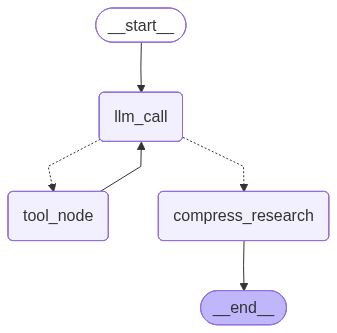

In [229]:
# Graph builder 

from IPython.display import Image , display

agent_builder = StateGraph(ResearcherState , output_schema=ResearcherOutputState)

agent_builder.add_node("llm_call" , llm_call)
agent_builder.add_node("tool_node",tool_node)
agent_builder.add_node("compress_research" , compress_research)

agent_builder.add_edge(START , "llm_call")
agent_builder.add_conditional_edges(
    "llm_call" ,
    should_continue , 
    {
        "tool_node" : "tool_node" , 
        "compress_research" : "compress_research"
    } ,
)
agent_builder.add_edge("tool_node" , "llm_call")
agent_builder.add_edge("compress_research" , END)

researcher_agent = agent_builder.compile()

display(Image(researcher_agent.get_graph().draw_mermaid_png()))

### Research Supervisor
The supervisor has a simple job: delegate research tasks to an appropriate number of sub-agents.

- multi-agent systems can split sub-topic to sub-agents with isolated context windows. I build a system where a supervisor determines if the research brief can be broken-down into independent sub-topics and delegates to sub-agents with isolated context windows.

In [230]:
lead_researcher_prompt = """You are a research supervisor. Your job is to conduct research by calling the "ConductResearch" tool. For context, today's date is {date}.

<Task>
Your focus is to call the "ConductResearch" tool to conduct research against the overall research question passed in by the user. 
When you are completely satisfied with the research findings returned from the tool calls, then you should call the "ResearchComplete" tool to indicate that you are done with your research.
</Task>

<Available Tools>
You have access to three main tools:
1. **ConductResearch**: Delegate research tasks to specialized sub-agents
2. **ResearchComplete**: Indicate that research is complete
3. **think_tool**: For reflection and strategic planning during research

**CRITICAL: Use think_tool before calling ConductResearch to plan your approach, and after each ConductResearch to assess progress**
**PARALLEL RESEARCH**: When you identify multiple independent sub-topics that can be explored simultaneously, make multiple ConductResearch tool calls in a single response to enable parallel research execution. This is more efficient than sequential research for comparative or multi-faceted questions. Use at most {max_concurrent_research_units} parallel agents per iteration.
</Available Tools>

<Instructions>
Think like a research manager with limited time and resources. Follow these steps:

1. **Read the question carefully** - What specific information does the user need?
2. **Decide how to delegate the research** - Carefully consider the question and decide how to delegate the research. Are there multiple independent directions that can be explored simultaneously?
3. **After each call to ConductResearch, pause and assess** - Do I have enough to answer? What's still missing?
</Instructions>

<Hard Limits>
**Task Delegation Budgets** (Prevent excessive delegation):
- **Bias towards single agent** - Use single agent for simplicity unless the user request has clear opportunity for parallelization
- **Stop when you can answer confidently** - Don't keep delegating research for perfection
- **Limit tool calls** - Always stop after {max_researcher_iterations} tool calls to think_tool and ConductResearch if you cannot find the right sources
</Hard Limits>

<Show Your Thinking>
Before you call ConductResearch tool call, use think_tool to plan your approach:
- Can the task be broken down into smaller sub-tasks?

After each ConductResearch tool call, use think_tool to analyze the results:
- What key information did I find?
- What's missing?
- Do I have enough to answer the question comprehensively?
- Should I delegate more research or call ResearchComplete?
</Show Your Thinking>

<Scaling Rules>
**Simple fact-finding, lists, and rankings** can use a single sub-agent:
- *Example*: List the top 10 coffee shops in San Francisco → Use 1 sub-agent

**Comparisons presented in the user request** can use a sub-agent for each element of the comparison:
- *Example*: Compare OpenAI vs. Anthropic vs. DeepMind approaches to AI safety → Use 3 sub-agents
- Delegate clear, distinct, non-overlapping subtopics

**Important Reminders:**
- Each ConductResearch call spawns a dedicated research agent for that specific topic
- A separate agent will write the final report - you just need to gather information
- When calling ConductResearch, provide complete standalone instructions - sub-agents can't see other agents' work
- Do NOT use acronyms or abbreviations in your research questions, be very clear and specific
</Scaling Rules>"""

In [231]:
import os 
from dotenv import load_dotenv
load_dotenv()

# Disable deprecated LangChain v1 tracer if present
os.environ.pop("LANGCHAIN_TRACING", None)

# Enable LangChain tracing v2 (optional; no-op without API key)
os.environ["LANGCHAIN_TRACING_V2"] = os.getenv("LANGCHAIN_TRACING_V2", "true")

# Set GROQ key from environment
os.environ["GROQ_API_KEY"] = groq_api_key = os.getenv("GROQ_API_KEY")

### State

In [232]:
import operator 
from typing_extensions import TypedDict 
from typing import Annotated , List , Sequence , Literal 
from langchain_core.messages import BaseMessage
from langchain_core.tools import tool
from langgraph.graph.message import add_messages 
from pydantic import  BaseModel , Field

In [233]:
class SupervisorState(TypedDict) : 
    """State for the multi-agent research supervisor."""

    # Messages exchanged with supervisor for coordination and decision-making
    supervisor_messages: Annotated[Sequence[BaseMessage], add_messages]
    # Detailed research brief that guides the overall research direction
    research_brief: str
    # Processed and structured notes ready for final report generation
    notes: Annotated[list[str], operator.add] = []
    # Counter tracking the number of research iterations performed
    research_iterations: int = 0
    # Raw unprocessed research notes collected from sub-agent research
    raw_notes: Annotated[list[str], operator.add] = []


In [234]:
@tool
class ConductResearch(BaseModel):
    """Tool for delegating a research task to a specialized sub-agent."""
    research_topic: str = Field(
        description="The topic to research. Should be a single topic, and should be described in high detail (at least a paragraph).",
    )

@tool
class ResearchComplete(BaseModel):
    """Tool for indicating that the research process is complete."""
    pass

### Multi-agent

- A multi-agent system is a system that consists of multiple agents that work together to complete a task.

In [235]:
import asyncio 

from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage , BaseMessage , SystemMessage , ToolMessage , filter_messages
from langgraph.graph import StateGraph , START , END 
from langgraph.types import Command


In [236]:
def get_notes_from_tool_calls(messages: list[BaseMessage]) -> list[str]:
    """Extract research notes from ToolMessage objects in supervisor message history.
    
    This function retrieves the compressed research findings that sub-agents
    return as ToolMessage content. When the supervisor delegates research to
    sub-agents via ConductResearch tool calls, each sub-agent returns its
    compressed findings as the content of a ToolMessage. This function
    extracts all such ToolMessage content to compile the final research notes.
    
    Args:
        messages: List of messages from supervisor's conversation history
        
    Returns:
        List of research note strings extracted from ToolMessage objects
    """
    return [tool_msg.content for tool_msg in filter_messages(messages, include_types="tool")]

try:
    import nest_asyncio

    try:
        from IPython import get_ipython
        if get_ipython() is not None:
            nest_asyncio.apply()
    except ImportError:
        pass  
except ImportError:
    pass  

In [237]:
supervisor_tools = [ConductResearch, ResearchComplete, think_tool]
supervisor_model = ChatGroq(model="meta-llama/llama-4-scout-17b-16e-instruct")
supervisor_model_with_tools = supervisor_model.bind_tools(supervisor_tools)

In [238]:
# This prevents infinite loops and controls research depth per topic
max_researcher_iterations = 6 # Calls to think_tool + ConductResearch


In [239]:
# This is passed to the lead_researcher_prompt to limit parallel research tasks
max_concurrent_researchers = 3

In [240]:
## Nodes 

async def supervisor(state: SupervisorState) -> Command[Literal["supervisor_tools"]]:
    """Coordinate research activities.
    
    Analyzes the research brief and current progress to decide:
    - What research topics need investigation
    - Whether to conduct parallel research
    - When research is complete
    
    Args:
        state: Current supervisor state with messages and research progress
        
    Returns:
        Command to proceed to supervisor_tools node with updated state
    """
    supervisor_messages = state.get("supervisor_messages", [])
    
    # Prepare system message with current date and constraints
    system_message = lead_researcher_prompt.format(
        date=get_today_str(), 
        max_concurrent_research_units=max_concurrent_researchers,
        max_researcher_iterations=max_researcher_iterations
    )
    messages = [SystemMessage(content=system_message)] + supervisor_messages
    
    # Make decision about next research steps
    response = await supervisor_model_with_tools.ainvoke(messages)
    
    return Command(
        goto="supervisor_tools",
        update={
            "supervisor_messages": [response],
            "research_iterations": state.get("research_iterations", 0) + 1
        }
    )

In [241]:
async def supervisor_tools(state: SupervisorState) -> Command[Literal["supervisor", "__end__"]]:
    """Execute supervisor decisions - either conduct research or end the process.
    
    Handles:
    - Executing think_tool calls for strategic reflection
    - Launching parallel research agents for different topics
    - Aggregating research results
    - Determining when research is complete
    
    Args:
        state: Current supervisor state with messages and iteration count
        
    Returns:
        Command to continue supervision, end process, or handle errors
    """
    supervisor_messages = state.get("supervisor_messages", [])
    research_iterations = state.get("research_iterations", 0)
    most_recent_message = supervisor_messages[-1]
    
    # Initialize variables for single return pattern
    tool_messages = []
    all_raw_notes = []
    next_step = "supervisor"  # Default next step
    should_end = False
    
    # Check exit criteria first
    exceeded_iterations = research_iterations >= max_researcher_iterations
    no_tool_calls = not most_recent_message.tool_calls
    research_complete = any(
        tool_call["name"] == "ResearchComplete" 
        for tool_call in most_recent_message.tool_calls
    )
    
    if exceeded_iterations or no_tool_calls or research_complete:
        should_end = True
        next_step = END
    
    else:
        
        try:
            # Separate think_tool calls from ConductResearch calls
            think_tool_calls = [
                tool_call for tool_call in most_recent_message.tool_calls 
                if tool_call["name"] == "think_tool"
            ]
            
            conduct_research_calls = [
                tool_call for tool_call in most_recent_message.tool_calls 
                if tool_call["name"] == "ConductResearch"
            ]

            # Handle think_tool calls (synchronous)
            for tool_call in think_tool_calls:
                observation = think_tool.invoke(tool_call["args"])
                tool_messages.append(
                    ToolMessage(
                        content=observation,
                        name=tool_call["name"],
                        tool_call_id=tool_call["id"]
                    )
                )

            # Handle ConductResearch calls (asynchronous)
            if conduct_research_calls:
                # Launch parallel research agents
                coros = [
                    researcher_agent.ainvoke({
                        "researcher_messages": [
                            HumanMessage(content=tool_call["args"]["research_topic"])
                        ],
                        "research_topic": tool_call["args"]["research_topic"]
                    }) 
                    for tool_call in conduct_research_calls
                ]

                # Wait for all research to complete
                tool_results = await asyncio.gather(*coros)

                # Format research results as tool messages
                # Each sub-agent returns compressed research findings in result["compressed_research"]
                # We write this compressed research as the content of a ToolMessage, which allows
                # the supervisor to later retrieve these findings via get_notes_from_tool_calls()
                research_tool_messages = [
                    ToolMessage(
                        content=result.get("compressed_research", "Error synthesizing research report"),
                        name=tool_call["name"],
                        tool_call_id=tool_call["id"]
                    ) for result, tool_call in zip(tool_results, conduct_research_calls)
                ]
                
                tool_messages.extend(research_tool_messages)

                # Aggregate raw notes from all research
                all_raw_notes = [
                    "\n".join(result.get("raw_notes", [])) 
                    for result in tool_results
                ]
                
        except Exception as e:
            print(f"Error in supervisor tools: {e}")
            should_end = True
            next_step = END
    
    # Single return point with appropriate state updates
    if should_end:
        return Command(
            goto=next_step,
            update={
                "notes": get_notes_from_tool_calls(supervisor_messages),
                "research_brief": state.get("research_brief", "")
            }
        )
    else:
        return Command(
            goto=next_step,
            update={
                "supervisor_messages": tool_messages,
                "raw_notes": all_raw_notes
            }
        )

In [242]:
# Build supervisor graph
supervisor_builder = StateGraph(SupervisorState)
supervisor_builder.add_node("supervisor", supervisor)
supervisor_builder.add_node("supervisor_tools", supervisor_tools)
supervisor_builder.add_edge(START, "supervisor")
supervisor_agent = supervisor_builder.compile()

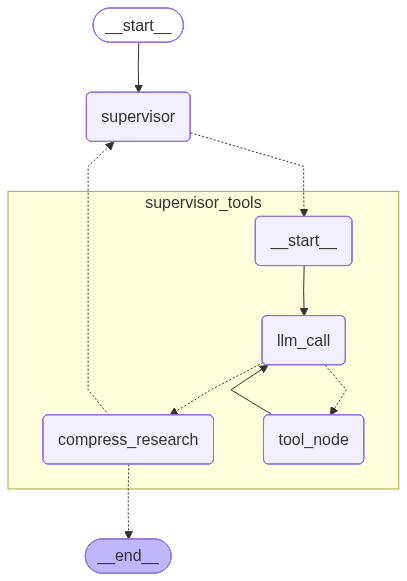

In [243]:
from IPython.display import Image, display

display(Image(supervisor_agent.get_graph(xray=True).draw_mermaid_png()))


### Multi-Agent Research 

This notebook combines all the previous components into a single system.

In [244]:
from langchain_core.messages import HumanMessage
from langgraph.graph import StateGraph, START, END

In [245]:
writer_model = ChatGroq(model="meta-llama/llama-4-scout-17b-16e-instruct", max_tokens=8192)

### FINAL REPORT GENERATION

In [246]:
final_report_generation_prompt = """Based on all the research conducted, create a comprehensive, well-structured answer to the overall research brief:
<Research Brief>
{research_brief}
</Research Brief>

CRITICAL: Make sure the answer is written in the same language as the human messages!
For example, if the user's messages are in English, then MAKE SURE you write your response in English. If the user's messages are in Chinese, then MAKE SURE you write your entire response in Chinese.
This is critical. The user will only understand the answer if it is written in the same language as their input message.

Today's date is {date}.

Here are the findings from the research that you conducted:
<Findings>
{findings}
</Findings>

Please create a detailed answer to the overall research brief that:
1. Is well-organized with proper headings (# for title, ## for sections, ### for subsections)
2. Includes specific facts and insights from the research
3. References relevant sources using [Title](URL) format
4. Provides a balanced, thorough analysis. Be as comprehensive as possible, and include all information that is relevant to the overall research question. People are using you for deep research and will expect detailed, comprehensive answers.
5. Includes a "Sources" section at the end with all referenced links

You can structure your report in a number of different ways. Here are some examples:

To answer a question that asks you to compare two things, you might structure your report like this:
1/ intro
2/ overview of topic A
3/ overview of topic B
4/ comparison between A and B
5/ conclusion

To answer a question that asks you to return a list of things, you might only need a single section which is the entire list.
1/ list of things or table of things
Or, you could choose to make each item in the list a separate section in the report. When asked for lists, you don't need an introduction or conclusion.
1/ item 1
2/ item 2
3/ item 3

To answer a question that asks you to summarize a topic, give a report, or give an overview, you might structure your report like this:
1/ overview of topic
2/ concept 1
3/ concept 2
4/ concept 3
5/ conclusion

If you think you can answer the question with a single section, you can do that too!
1/ answer

REMEMBER: Section is a VERY fluid and loose concept. You can structure your report however you think is best, including in ways that are not listed above!
Make sure that your sections are cohesive, and make sense for the reader.

For each section of the report, do the following:
- Use simple, clear language
- Use ## for section title (Markdown format) for each section of the report
- Do NOT ever refer to yourself as the writer of the report. This should be a professional report without any self-referential language. 
- Do not say what you are doing in the report. Just write the report without any commentary from yourself.
- Each section should be as long as necessary to deeply answer the question with the information you have gathered. It is expected that sections will be fairly long and verbose. You are writing a deep research report, and users will expect a thorough answer.
- Use bullet points to list out information when appropriate, but by default, write in paragraph form.

REMEMBER:
The brief and research may be in English, but you need to translate this information to the right language when writing the final answer.
Make sure the final answer report is in the SAME language as the human messages in the message history.

Format the report in clear markdown with proper structure and include source references where appropriate.

<Citation Rules>
- Assign each unique URL a single citation number in your text
- End with ### Sources that lists each source with corresponding numbers
- IMPORTANT: Number sources sequentially without gaps (1,2,3,4...) in the final list regardless of which sources you choose
- Each source should be a separate line item in a list, so that in markdown it is rendered as a list.
- Example format:
  [1] Source Title: URL
  [2] Source Title: URL
- Citations are extremely important. Make sure to include these, and pay a lot of attention to getting these right. Users will often use these citations to look into more information.
</Citation Rules>
"""

In [247]:
async def final_report_generation(state: AgentState):
    """
    Final report generation node.
    
    Synthesizes all research findings into a comprehensive final report
    """
    
    notes = state.get("notes", [])
    
    findings = "\n".join(notes)

    final_report_prompt = final_report_generation_prompt.format(
        research_brief=state.get("research_brief", ""),
        findings=findings,
        date=get_today_str()
    )
    
    final_report = await writer_model.ainvoke([HumanMessage(content=final_report_prompt)])
    
    return {
        "final_report": final_report.content, 
        "messages": ["Here is the final report: " + final_report.content],
    }

In [248]:
# Build the overall workflow
deep_researcher_builder = StateGraph(AgentState, input_schema=AgentInputState)

# Add workflow nodes
deep_researcher_builder.add_node("clarify_with_user", clarify_with_user)
deep_researcher_builder.add_node("write_research_brief", write_research_brief)
deep_researcher_builder.add_node("supervisor_subgraph", supervisor_agent)
deep_researcher_builder.add_node("final_report_generation", final_report_generation)

# Add workflow edges
deep_researcher_builder.add_edge(START, "clarify_with_user")
deep_researcher_builder.add_edge("write_research_brief", "supervisor_subgraph")
deep_researcher_builder.add_edge("supervisor_subgraph", "final_report_generation")
deep_researcher_builder.add_edge("final_report_generation", END)

# Compile the full workflow
agent = deep_researcher_builder.compile()

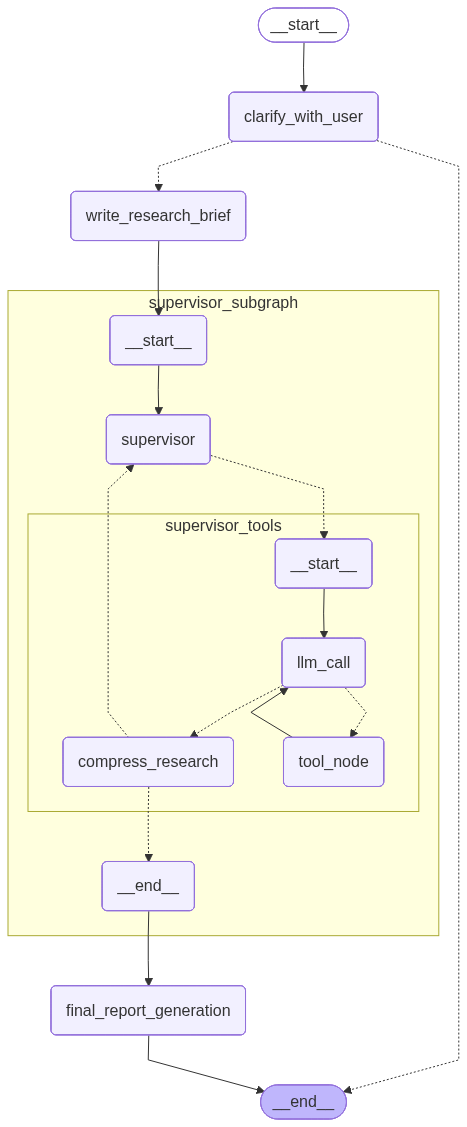

In [249]:
# Run the workflow
from IPython.display import Image, display
from langgraph.checkpoint.memory import InMemorySaver

checkpointer = InMemorySaver()
full_agent = deep_researcher_builder.compile(checkpointer=checkpointer)
display(Image(full_agent.get_graph(xray=True).draw_mermaid_png()))


In [250]:
from langchain_core.messages import HumanMessage
thread = {"configurable": {"thread_id": "1", "recursion_limit": 50}}
result = await full_agent.ainvoke({"messages": [HumanMessage(content="Compare Gemini to OpenAI Deep Research agents.")]}, config=thread)
for msg in result['messages'] : 
    msg.pretty_print()

================================ Human Message =================================

Compare Gemini to OpenAI Deep Research agents.
================================== Ai Message ==================================

To compare Gemini and OpenAI Deep Research agents, can you please clarify what specific aspects you would like me to focus on (e.g., capabilities, features, performance, applications)?


In [251]:
result = await full_agent.ainvoke({"messages": [HumanMessage(content="Yes the specific Deep Research products.")]}, config=thread)


Error in supervisor tools: Error code: 400 - {'error': {'message': "Failed to call a function. Please adjust your prompt. See 'failed_generation' for more details.", 'type': 'invalid_request_error', 'code': 'tool_use_failed', 'failed_generation': '[\n  {\n    "name": "think_tool",\n    "parameters": {\n      "reflection": "The search results provide valuable information about OpenAI\'s Deep Research, including its capabilities, features, performance, and applications. Key points include:\n\n1. Deep Research is an advanced AI agent designed for multi-step investigations, capable of browsing the web, analyzing multiple sources, and synthesizing large volumes of information.\n2. It is powered by an advanced version of OpenAI\'s upcoming O3 model, leveraging the latest innovations in AI reasoning and web-based data analysis.\n3. Deep Research has demonstrated impressive performance, setting a new accuracy record of 26.6% in the Humanity\'s Last Exam benchmark and securing the top position 

In [252]:
for msg in result['messages'] : 
    msg.pretty_print()

================================ Human Message =================================

Compare Gemini to OpenAI Deep Research agents.
================================== Ai Message ==================================

To compare Gemini and OpenAI Deep Research agents, can you please clarify what specific aspects you would like me to focus on (e.g., capabilities, features, performance, applications)?
================================ Human Message =================================

Yes the specific Deep Research products.
================================== Ai Message ==================================

I have sufficient information to proceed. You would like me to compare Gemini and OpenAI Deep Research agents, specifically focusing on their Deep Research products. I will now begin the research process.
================================ Human Message =================================

Here is the final report: # Comparison of Google Gemini Deep Research and OpenAI Deep Research Agents

## Overvi

In [253]:
from IPython.display import Markdown 

Markdown(result['final_report'])

# Comparison of Google Gemini Deep Research and OpenAI Deep Research Agents

## Overview of Google Gemini Deep Research

Google Gemini Deep Research is an AI-powered research tool that conducts autonomous, multi-hour investigations across hundreds of sources to create comprehensive research reports. It was released as part of Gemini 2.0 in December 2024 and has since been enhanced with new features in May 2025, including PDF and image upload capabilities and audio overviews [1].

### Key Features of Google Gemini Deep Research

*   **Multi-hour autonomous research**: Conducts in-depth research across multiple sources.
*   **Interactive research plans**: Allows users to engage with the research process.
*   **Export-ready reports**: Provides comprehensive reports with key findings and links to original sources.
*   **Gemini 3 Pro model**: Uses a factual model trained to reduce hallucinations and maximize report quality.

### Applications of Google Gemini Deep Research

The tool is designed for various applications, including:

*   **Market research**: Analyzes market trends and provides insights.
*   **Academic literature reviews**: Conducts comprehensive reviews of academic literature.
*   **Technical documentation**: Assists with technical documentation and research.
*   **Business strategy**: Provides insights for business strategy and decision-making.

### Pricing and Accessibility

Gemini Deep Research costs $20/month for Gemini Advanced, which includes unlimited Deep Research queries, access to Gemini 2.5 Flash, and other features. Google has also reimagined Gemini Deep Research to be more powerful and accessible to developers via the new Interactions API, optimized for long-running context gathering and synthesis tasks [1][2].

## Overview of OpenAI Deep Research Agents

There is limited information available on OpenAI Deep Research agents. However, OpenAI is known for its language models, including ChatGPT, which can be used for research and analysis.

## Comparison of Google Gemini Deep Research and OpenAI Deep Research Agents

Since there is limited information available on OpenAI Deep Research agents, a comprehensive comparison between Google Gemini Deep Research and OpenAI Deep Research agents cannot be made. However, based on the available information, Google Gemini Deep Research appears to be a more developed and feature-rich tool, specifically designed for deep research and analysis.

### Key Differences

*   **Autonomous research capabilities**: Google Gemini Deep Research has autonomous, multi-hour research capabilities, while OpenAI's research agents may rely on user input and guidance.
*   **Integration with other tools**: Google Gemini Deep Research has integration with other Google tools, such as Gemini 2.5 Flash, and provides export-ready reports.

## Conclusion

Google Gemini Deep Research is a powerful tool for deep research and analysis, with a range of features and applications. While there is limited information available on OpenAI Deep Research agents, Google Gemini Deep Research appears to be a more developed and feature-rich tool. Further research is needed to fully compare and evaluate the capabilities and performance of OpenAI Deep Research agents.

### Sources

[1] Digital Applied: Google Gemini Deep Research: Complete Guide 2025 - https://www.digitalapplied.com/blog/google-gemini-deep-research-guide

[2] Google Blog: Build with Gemini Deep Research - https://blog.google/technology/developers/deep-research-agent-gemini-api/

[3] Google Blog: Try Deep Research and Gemini 2.0 Flash Experimental - https://blog.google/products/gemini/google-gemini-deep-research/